# Machine Learning: Dimensionality Reduction & PCA
## Comprehensive Study Guide, Mathematical Foundations & Implementations

---

### Table of Contents:
1. **Introduction to Dimensionality Reduction**
   - The Curse of Dimensionality
   - Feature Selection vs. Feature Extraction
2. **Principal Component Analysis (PCA) Fundamentals**
   - Intuition & Geometric Interpretation
   - Why Feature Standardization is Mandatory
   - Covariance Matrix, Eigenvalues & Eigenvectors
3. **Step-by-Step Implementation of PCA from Scratch (NumPy)**
   - Mathematical Steps 1 through 5
   - Comparison with Scikit-Learn (Proof of Equivalence)
4. **PCA using Scikit-Learn (`sklearn.decomposition.PCA`)**
   - 4D to 2D Iris Dataset Projection & 2D Visualization
   - Interpreting `explained_variance_ratio_` and `components_`
5. **Determining the Optimal Number of Components**
   - Scree Plot & Cumulative Explained Variance (Breast Cancer Dataset - 30D)
   - Retaining 95% Variance Rule
6. **PCA in Machine Learning Pipeline**
   - Speed, Multicollinearity & Performance Comparison (Logistic Regression)
7. **Data Reconstruction & Compression (Lossy Inversion)**
8. **Summary, Advantages, Limitations & Exam Cheatsheet**


---
# 1. Introduction to Dimensionality Reduction

### What is Dimensionality Reduction?
In machine learning, **dimensionality** refers to the number of input features or variables in a dataset ($p$ or $d$ dimensions for $n$ samples, shape $n \times d$).

**Dimensionality Reduction** is the process of transforming data from a high-dimensional space into a lower-dimensional representation ($k \ll d$) while preserving as much meaningful information, structure, and variance as possible.

### Why do we need it? The "Curse of Dimensionality"
As the number of dimensions $d$ grows:
1. **Data Sparsity**: The volume of the feature space increases exponentially ($V \propto 2^d$). The available data points become extremely sparse, requiring exponentially more training samples to avoid overfitting.
2. **Distance Metric Breakdown**: In high dimensions, Euclidean distance between any two random points converges to roughly the same value:
   $$\lim_{d \to \infty} \frac{\text{dist}_{\max} - \text{dist}_{\min}}{\text{dist}_{\min}} \to 0$$
   This degrades distance-based algorithms like KNN, K-Means, and SVM.
3. **Multicollinearity & Redundancy**: Many features correlate strongly with each other, adding computational burden and noise without new signal.
4. **Visualization Constraints**: Humans can only intuitively visualize data in 1D, 2D, or 3D. Dimensionality reduction allows us to plot complex datasets.

### Feature Selection vs. Feature Extraction
| Aspect | Feature Selection | Feature Extraction (e.g., PCA) |
| :--- | :--- | :--- |
| **Method** | Chooses a subset of existing features without altering them | Creates brand new composite features from linear/nonlinear combinations |
| **Examples** | VarianceThreshold, SelectKBest, RFE | PCA, LDA, t-SNE, UMAP, Autoencoders |
| **Interpretability** | High (original feature names kept) | Moderate/Low (components are combinations of all features) |
| **Information Loss**| Discarded features lose 100% of their unique variance | Retains maximum collective variance across all original features |


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.datasets import load_iris, load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
import time

# Plotting configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['font.size'] = 11

print("All libraries successfully imported!")


All libraries successfully imported!


---
# 2. Principal Component Analysis (PCA) Fundamentals

### What is PCA?
**Principal Component Analysis (PCA)** is an unsupervised, linear dimensionality reduction technique invented by Karl Pearson in 1901.

PCA seeks new orthogonal (uncorrelated) axes called **Principal Components (PCs)** such that:
- **PC1 (1st Principal Component)**: Points in the direction of **maximum variance** in the data.
- **PC2 (2nd Principal Component)**: Perpendicular (orthogonal) to PC1 and captures the **second highest variance**.
- **PC$k$**: Orthogonal to all preceding PCs, capturing progressively smaller remaining variance.

### Geometric Intuition
Imagine a 2D cloud of data shaped like an elongated ellipse:
- Rather than describing points using the original axes $(X_1, X_2)$, PCA rotates the coordinate system.
- The major axis of the ellipse becomes **PC1** (capturing ~90% of variance).
- The minor axis becomes **PC2** (capturing ~10% of variance).
- If we drop PC2, we project the 2D ellipse onto a 1D line while keeping 90% of the information!

### Why Feature Scaling (Standardization) is Strictly Mandatory
Because PCA seeks to maximize variance:
- If Feature A has values between 1 and 1000 (variance $\approx 10^5$), and Feature B has values between 0.01 and 0.1 (variance $\approx 10^{-3}$), PCA will align PC1 almost entirely with Feature A simply because of its scale!
- Therefore, we **must** standardize every feature to zero mean and unit variance:
$$Z = \frac{X - \mu}{\sigma}$$


---
# 3. Mathematical Workflow & PCA from Scratch (NumPy)

### Mathematical Steps:
1. **Standardize Data Matrix $X$**:
   $$Z = \frac{X - \mu}{\sigma} \quad (n \times d)$$
2. **Compute Covariance Matrix $\Sigma$**:
   $$\Sigma = \frac{1}{n-1} Z^T Z \quad (d \times d)$$
   - Diagonal elements: Variance of each feature.
   - Off-diagonal elements: Covariance between pairs of features.
3. **Compute Eigenvalues & Eigenvectors**:
   $$\Sigma v = \lambda v$$
   - **Eigenvector ($v$)**: The geometric direction of the principal component axis.
   - **Eigenvalue ($\lambda$)**: The magnitude of variance along that direction.
4. **Sort and Select Top $k$ Eigenvectors**:
   - Sort $\lambda_1 \ge \lambda_2 \ge \dots \ge \lambda_d$.
   - Select top $k$ eigenvectors to construct projection matrix $W \in \mathbb{R}^{d \times k}$.
5. **Project Original Data into $k$ Dimensions**:
   $$Z_{\text{PCA}} = Z \cdot W \quad (n \times k)$$


In [2]:
# --- Step-by-Step Implementation of PCA from Scratch ---

# 1. Load sample dataset (Iris Dataset: 150 samples, 4 features)
iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names
target_names = iris.target_names

print(f"Original shape: {X.shape} (150 samples, 4 features)")

# Step 1: Standardize features (mean=0, std=1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Step 2: Compute Covariance Matrix (d x d)
# Note: np.cov expects features as rows, so we transpose X_scaled
cov_matrix = np.cov(X_scaled.T)
print("\nCovariance Matrix (4x4):")
print(np.round(cov_matrix, 3))

# Step 3: Compute Eigenvalues and Eigenvectors (using eigh for symmetric matrices)
eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)
print("\nEigenvalues:", np.round(eigenvalues, 4))
print("Eigenvectors shape:", eigenvectors.shape)

# Step 4: Sort Eigenvalues & Eigenvectors in descending order
sorted_indices = np.argsort(eigenvalues)[::-1]
eigenvalues_sorted = eigenvalues[sorted_indices]
eigenvectors_sorted = eigenvectors[:, sorted_indices]

# Explained Variance Ratio per component
explained_var_ratio = eigenvalues_sorted / np.sum(eigenvalues_sorted)
print("\nExplained Variance Ratio (from scratch):", np.round(explained_var_ratio, 4))

# Select top k=2 eigenvectors (Projection Matrix W)
k = 2
W = eigenvectors_sorted[:, :k]
print(f"\nProjection Matrix W shape (d x k): {W.shape}")

# Step 5: Transform data into 2D
X_pca_scratch = np.dot(X_scaled, W)
print(f"Transformed Data Shape: {X_pca_scratch.shape}")


Original shape: (150, 4) (150 samples, 4 features)

Covariance Matrix (4x4):
[[ 1.007 -0.118  0.878  0.823]
 [-0.118  1.007 -0.431 -0.369]
 [ 0.878 -0.431  1.007  0.969]
 [ 0.823 -0.369  0.969  1.007]]

Eigenvalues: [0.0209 0.1477 0.9202 2.9381]
Eigenvectors shape: (4, 4)

Explained Variance Ratio (from scratch): [0.7296 0.2285 0.0367 0.0052]

Projection Matrix W shape (d x k): (4, 2)
Transformed Data Shape: (150, 2)


### Verify Scratch Implementation Against Scikit-Learn
*Note: Eigenvectors define an axis direction, so a component may differ by a sign flip ($v$ vs. $-v$), but the subspace and absolute projections are identical.*


In [3]:
# Compare Scratch with Scikit-Learn PCA
pca_sklearn = PCA(n_components=2)
X_pca_sklearn = pca_sklearn.fit_transform(X_scaled)

print("Scikit-Learn Explained Variance Ratio:", np.round(pca_sklearn.explained_variance_ratio_, 4))
print("Scratch Explained Variance Ratio:     ", np.round(explained_var_ratio[:2], 4))

# Maximum absolute difference (accounting for potential sign flip)
diff = np.max(np.abs(np.abs(X_pca_scratch) - np.abs(X_pca_sklearn)))
print(f"\nMax Absolute Difference between Scratch & Scikit-Learn: {diff:.2e}")
print("=> Proof of Exact Mathematical Equivalence!")


Scikit-Learn Explained Variance Ratio: [0.7296 0.2285]
Scratch Explained Variance Ratio:      [0.7296 0.2285]

Max Absolute Difference between Scratch & Scikit-Learn: 4.44e-15
=> Proof of Exact Mathematical Equivalence!


---
# 4. In-Depth Scikit-Learn PCA & 2D Visualization

### Visualizing 4D Iris Data in 2D Space
By projecting 4 features (`sepal length`, `sepal width`, `petal length`, `petal width`) down to 2 principal components, we can visualize the entire dataset on a 2D scatter plot while retaining **~95.8% of the total variance**!


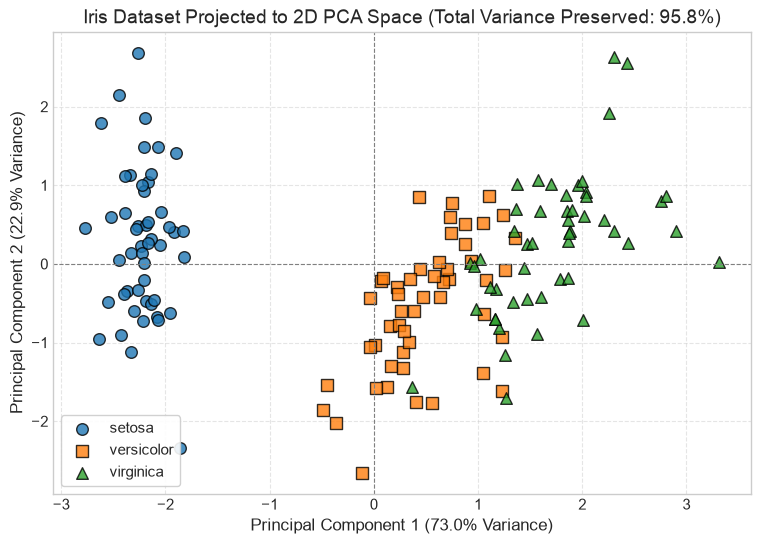

In [4]:
# Create a DataFrame for visualization
df_pca = pd.DataFrame(data=X_pca_sklearn, columns=['PC1', 'PC2'])
df_pca['Species'] = [target_names[i] for i in y]

var_pc1 = pca_sklearn.explained_variance_ratio_[0] * 100
var_pc2 = pca_sklearn.explained_variance_ratio_[1] * 100

plt.figure(figsize=(9, 6))
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']
markers = ['o', 's', '^']

for i, target in enumerate(target_names):
    subset = df_pca[df_pca['Species'] == target]
    plt.scatter(subset['PC1'], subset['PC2'],
                label=target, color=colors[i], marker=markers[i],
                alpha=0.8, edgecolors='k', s=70)

plt.title(f"Iris Dataset Projected to 2D PCA Space (Total Variance Preserved: {var_pc1 + var_pc2:.1f}%)", fontsize=14)
plt.xlabel(f"Principal Component 1 ({var_pc1:.1f}% Variance)", fontsize=12)
plt.ylabel(f"Principal Component 2 ({var_pc2:.1f}% Variance)", fontsize=12)
plt.axhline(0, color='grey', linestyle='--', linewidth=0.8)
plt.axvline(0, color='grey', linestyle='--', linewidth=0.8)
plt.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


### Interpreting Component Loadings (`pca.components_`)
Each Principal Component is a linear combination of original features:
$$PC_i = w_{i1} X_1 + w_{i2} X_2 + \dots + w_{id} X_d$$
The coefficients $w$ are called **loadings**. They indicate which original features contribute most to each component.


Principal Component Loadings (Weights):
     sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
PC1              0.521            -0.269              0.580             0.565
PC2              0.377             0.923              0.024             0.067


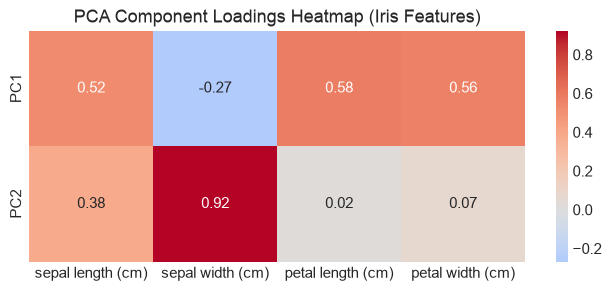

In [5]:
loadings = pd.DataFrame(
    pca_sklearn.components_,
    columns=feature_names,
    index=['PC1', 'PC2']
).round(3)

print("Principal Component Loadings (Weights):")
print(loadings)

# Heatmap of loadings
plt.figure(figsize=(8, 3))
sns.heatmap(loadings, annot=True, cmap='coolwarm', center=0, cbar=True, fmt='.2f')
plt.title("PCA Component Loadings Heatmap (Iris Features)")
plt.show()


---
# 5. Determining the Optimal Number of Components

### How do we choose $k$?
In higher-dimensional real-world datasets (e.g. 30, 100, or 1,000 features), we determine optimal $k$ using:
1. **The Scree Plot**: Plot of individual explained variance vs. component number. Look for the "elbow point".
2. **Cumulative Explained Variance Rule**: Choose the minimum $k$ that retains a target percentage of total variance (e.g., **90%** or **95%**).

Let's test this on the **Breast Cancer Wisconsin Dataset** (30 features, 569 samples).


Breast Cancer Dataset Shape: (569, 30) (30 features)
Components needed for >= 90% variance: 7 (out of 30)
Components needed for >= 95% variance: 10 (out of 30)


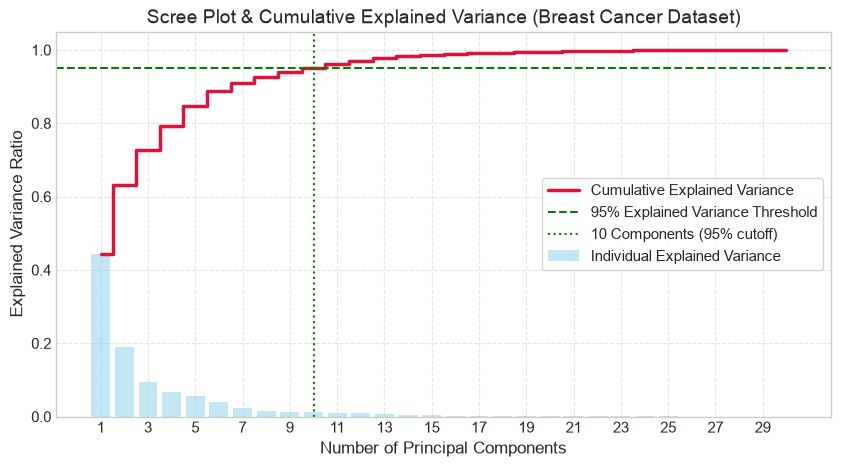

In [6]:
# Load Breast Cancer Dataset (30 dimensions)
cancer = load_breast_cancer()
X_c = cancer.data
y_c = cancer.target

print(f"Breast Cancer Dataset Shape: {X_c.shape} (30 features)")

# Standardize
scaler_c = StandardScaler()
X_c_scaled = scaler_c.fit_transform(X_c)

# Fit PCA with all 30 components
pca_full = PCA()
pca_full.fit(X_c_scaled)

explained_var = pca_full.explained_variance_ratio_
cum_explained_var = np.cumsum(explained_var)

# Find components needed for 95% variance
k_95 = np.argmax(cum_explained_var >= 0.95) + 1
k_90 = np.argmax(cum_explained_var >= 0.90) + 1

print(f"Components needed for >= 90% variance: {k_90} (out of 30)")
print(f"Components needed for >= 95% variance: {k_95} (out of 30)")

# Plot Cumulative Explained Variance
plt.figure(figsize=(10, 5))
plt.bar(range(1, 31), explained_var, alpha=0.5, align='center', label='Individual Explained Variance', color='skyblue')
plt.step(range(1, 31), cum_explained_var, where='mid', label='Cumulative Explained Variance', color='crimson', linewidth=2.5)

# Horizontal reference lines
plt.axhline(y=0.95, color='green', linestyle='--', label='95% Explained Variance Threshold')
plt.axvline(x=k_95, color='green', linestyle=':', label=f'{k_95} Components (95% cutoff)')

plt.title("Scree Plot & Cumulative Explained Variance (Breast Cancer Dataset)", fontsize=14)
plt.xlabel("Number of Principal Components", fontsize=12)
plt.ylabel("Explained Variance Ratio", fontsize=12)
plt.xticks(range(1, 31, 2))
plt.ylim(0, 1.05)
plt.legend(loc='center right', frameon=True, facecolor='white')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


### Automated Component Selection in Scikit-Learn
Instead of an integer $k$, you can pass a float between 0.0 and 1.0 into `PCA(n_components=0.95)` to automatically choose the smallest number of components that preserve 95% variance!


In [7]:
# Automatically preserve 95% variance
pca_auto = PCA(n_components=0.95)
X_c_pca = pca_auto.fit_transform(X_c_scaled)

print(f"Original feature count:       {X_c_scaled.shape[1]}")
print(f"PCA reduced feature count:    {X_c_pca.shape[1]}")
print(f"Actual variance retained:     {np.sum(pca_auto.explained_variance_ratio_)*100:.2f}%")
print(f"Dimensionality reduction:     {(1 - X_c_pca.shape[1]/X_c_scaled.shape[1])*100:.1f}% reduction in size!")


Original feature count:       30
PCA reduced feature count:    10
Actual variance retained:     95.16%
Dimensionality reduction:     66.7% reduction in size!


---
# 6. PCA in a Machine Learning Pipeline (Classification Benchmark)

Does reducing 30 features to 10 features hurt model accuracy?
Let's benchmark **Logistic Regression** on:
1. **Original 30 Features**
2. **PCA Reduced 10 Features (95% variance)**


In [8]:
# Train / Test split (75% train, 25% test)
X_train, X_test, y_train, y_test = train_test_split(
    X_c_scaled, y_c, test_size=0.25, random_state=42, stratify=y_c
)

# 1. Model on Original 30 features
clf_orig = LogisticRegression(max_iter=1000, random_state=42)
start_time = time.time()
clf_orig.fit(X_train, y_train)
orig_train_time = time.time() - start_time
y_pred_orig = clf_orig.predict(X_test)
acc_orig = accuracy_score(y_test, y_pred_orig)

# 2. Model on PCA-reduced 10 features
# Fit PCA ONLY on training data, then transform both train and test to prevent data leakage!
pca_pipe = PCA(n_components=k_95)
X_train_pca = pca_pipe.fit_transform(X_train)
X_test_pca = pca_pipe.transform(X_test)

clf_pca = LogisticRegression(max_iter=1000, random_state=42)
start_time = time.time()
clf_pca.fit(X_train_pca, y_train)
pca_train_time = time.time() - start_time
y_pred_pca = clf_pca.predict(X_test_pca)
acc_pca = accuracy_score(y_test, y_pred_pca)

# Comparison Summary
comparison_df = pd.DataFrame({
    'Metric': ['Number of Features', 'Training Time (sec)', 'Test Accuracy (%)'],
    'Original Data': [X_train.shape[1], f"{orig_train_time:.5f}", f"{acc_orig*100:.2f}%"],
    'PCA Reduced Data': [X_train_pca.shape[1], f"{pca_train_time:.5f}", f"{acc_pca*100:.2f}%"]
})
print("Performance Comparison:")
print(comparison_df.to_string(index=False))


Performance Comparison:
             Metric Original Data PCA Reduced Data
 Number of Features            30               10
Training Time (sec)       0.01848          0.00149
  Test Accuracy (%)        98.60%           97.90%


---
# 7. Data Reconstruction & Compression (Lossy Inversion)

PCA can be used as a lossy compression technique:
1. **Compress**: $X_{\text{reduced}} = Z \cdot W$
2. **Reconstruct**: $Z_{\text{approx}} = X_{\text{reduced}} \cdot W^T$
3. **Denormalize**: $X_{\text{reconstructed}} = Z_{\text{approx}} \cdot \sigma + \mu$

In Scikit-Learn, this is performed with `pca.inverse_transform()`:
$$\text{Reconstruction Error} = \| X_{\text{original}} - X_{\text{reconstructed}} \|^2$$


In [9]:
# Reconstructing Breast Cancer data from 10 components back to 30 features
X_reconstructed = pca_pipe.inverse_transform(X_test_pca)

# Mean Squared Reconstruction Error
reconstruction_error = np.mean((X_test - X_reconstructed) ** 2)
print(f"Number of components used: {k_95} / 30")
print(f"Mean Squared Reconstruction Error: {reconstruction_error:.4f}")

# Compare original vs reconstructed for the first sample
sample_comparison = pd.DataFrame({
    'Feature': cancer.feature_names[:6],
    'Original (Standardized)': np.round(X_test[0, :6], 3),
    'Reconstructed': np.round(X_reconstructed[0, :6], 3)
})
print("\nFirst 6 features of Sample 0 (Original vs. Reconstructed):")
print(sample_comparison.to_string(index=False))


Number of components used: 10 / 30
Mean Squared Reconstruction Error: 0.0541

First 6 features of Sample 0 (Original vs. Reconstructed):
         Feature  Original (Standardized)  Reconstructed
     mean radius                   -0.391         -0.529
    mean texture                   -0.603         -0.688
  mean perimeter                   -0.390         -0.521
       mean area                   -0.458         -0.475
 mean smoothness                    1.149          0.828
mean compactness                    0.139         -0.130


---
# 8. Summary & Key Takeaways for Exams / Interviews

### When to Use PCA:
- When you suffer from the **Curse of Dimensionality** ($p \gg 1$).
- When features exhibit **severe multicollinearity** (PCA produces strictly uncorrelated components).
- When you need to **visualize high-dimensional data** (projecting onto 2D or 3D).
- When training algorithms are computationally slow or memory-constrained.
- To reduce noise and mitigate overfitting.

### Key Limitations to Remember:
1. **Linearity Assumption**: PCA only captures linear correlations. For complex manifold structures, non-linear techniques (Kernel PCA, t-SNE, UMAP, Autoencoders) are required.
2. **Loss of Interpretability**: Principal components are linear combinations of all input features; individual feature names and exact physical meanings are lost.
3. **Information Loss**: Dropping lower components permanently discards some variance (often noise, but sometimes subtle signals).
4. **Sensitive to Outliers & Scaling**: Because it maximizes variance, unscaled data or extreme outliers can skew the principal components significantly. Always use `StandardScaler`!

### Quick Formula Reference Cheatsheet:
- **Standardization**: $Z = \frac{X - \mu}{\sigma}$
- **Covariance Matrix**: $\Sigma = \frac{1}{n-1} Z^T Z$
- **Eigen Decomposition**: $\Sigma v_i = \lambda_i v_i$
- **Explained Variance Ratio**: $\text{EVR}_i = \frac{\lambda_i}{\sum_{j=1}^d \lambda_j}$
- **Projection**: $Z_{\text{PCA}} = Z \cdot W$
- **Reconstruction**: $Z_{\text{approx}} = Z_{\text{PCA}} \cdot W^T$
